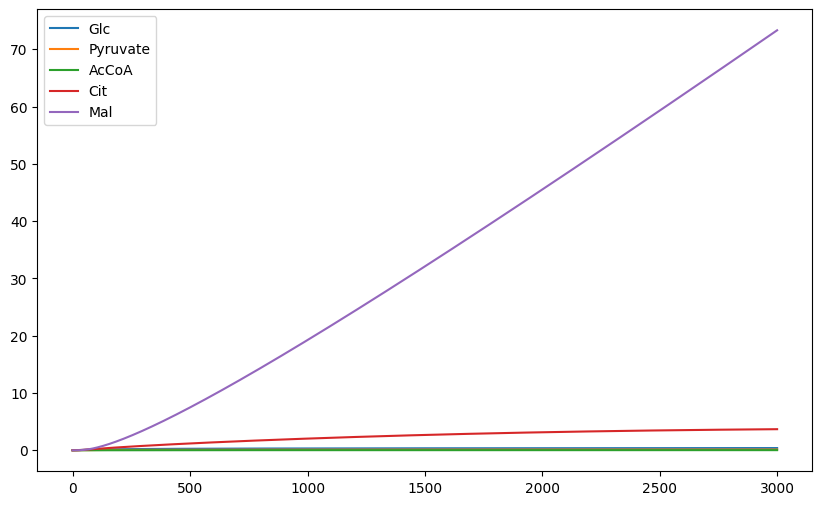

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from model_interface import *
from kinetics import *

state = DEFAULT_STATE.copy()

hist = []

for i in range(3000):

    state, flux = step_ivp_once(
        state,
        glu_in=1.0,
        fat_in=0.0,
        atp_draw=0.0
    )

    hist.append(state.copy())

hist = np.array(hist)

plt.figure(figsize=(10,6))

plt.plot(hist[:, STATE_INDEX["Glc"]], label="Glc")
plt.plot(hist[:, STATE_INDEX["Pyruvate"]], label="Pyruvate")
plt.plot(hist[:, STATE_INDEX["AcCoA"]], label="AcCoA")
plt.plot(hist[:, STATE_INDEX["Cit"]], label="Cit")
plt.plot(hist[:, STATE_INDEX["Mal"]], label="Mal")

plt.legend()
plt.show()

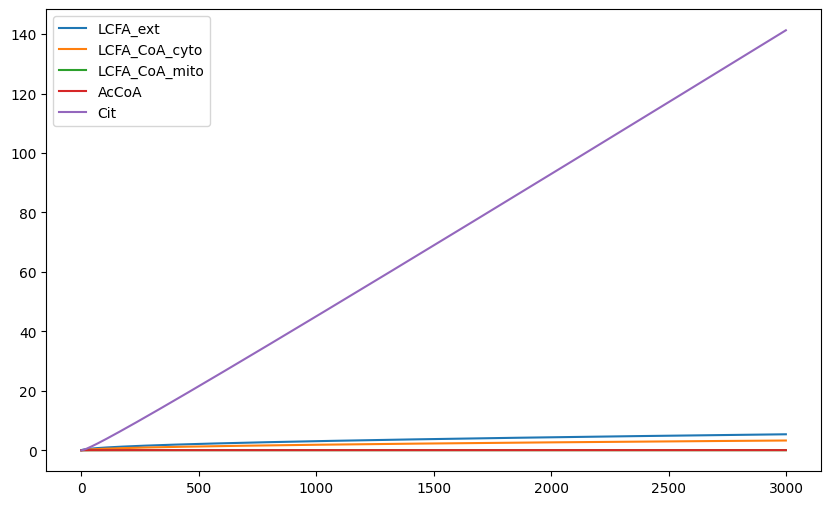

In [2]:
state = DEFAULT_STATE.copy()

hist = []

for i in range(3000):

    state, flux = step_ivp_once(
        state,
        glu_in=0.0,
        fat_in=1.0,
        atp_draw=0.0
    )

    hist.append(state.copy())

hist = np.array(hist)

plt.figure(figsize=(10,6))

plt.plot(hist[:, STATE_INDEX["LCFA_ext"]], label="LCFA_ext")
plt.plot(hist[:, STATE_INDEX["LCFA_CoA_cyto"]], label="LCFA_CoA_cyto")
plt.plot(hist[:, STATE_INDEX["LCFA_CoA_mito"]], label="LCFA_CoA_mito")
plt.plot(hist[:, STATE_INDEX["AcCoA"]], label="AcCoA")
plt.plot(hist[:, STATE_INDEX["Cit"]], label="Cit")

plt.legend()
plt.show()

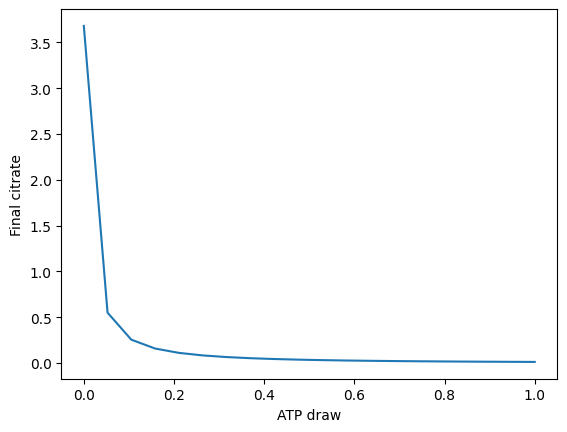

In [3]:
draw_values = np.linspace(
    0,
    1,
    20
)

cit_final = []

for draw in draw_values:

    state = DEFAULT_STATE.copy()

    for i in range(3000):

        state, flux = step_ivp_once(
            state,
            glu_in=1.0,
            fat_in=0.0,
            atp_draw=draw
        )

    cit_final.append(
        state[STATE_INDEX["Cit"]]
    )

plt.plot(draw_values, cit_final)
plt.xlabel("ATP draw")
plt.ylabel("Final citrate")
plt.show()

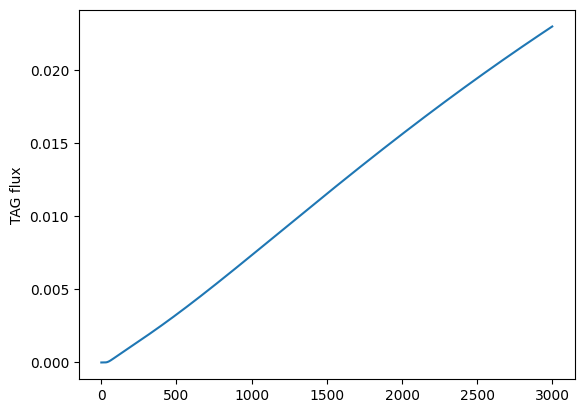

In [4]:
state = DEFAULT_STATE.copy()

tag_hist = []

for i in range(3000):

    state, flux = step_ivp_once(
        state,
        glu_in=1.0,
        fat_in=0.0,
        atp_draw=0.0
    )

    tag_hist.append(
        kinetics.v_TAG(
            state[STATE_INDEX["LCFA_CoA_cyto"]],
            state[STATE_INDEX["Glc"]]
        )
    )

plt.plot(tag_hist)
plt.ylabel("TAG flux")
plt.show()

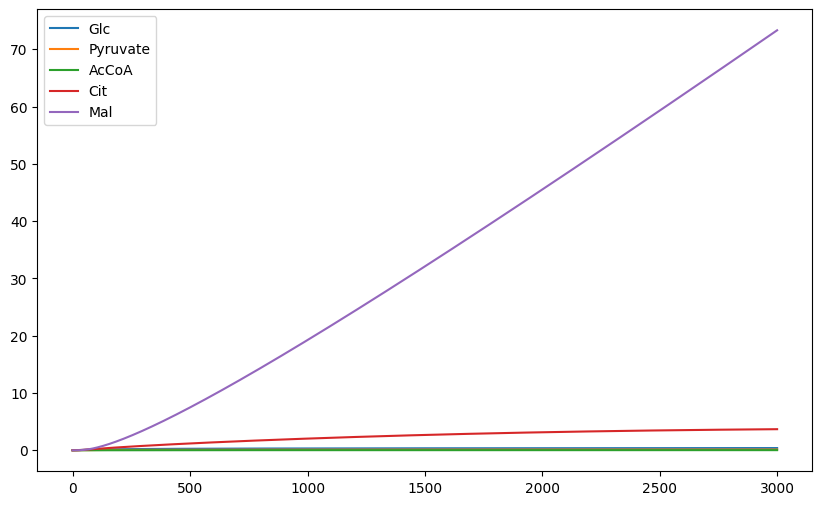


FINAL STATES
----------------------------------------
Glc_ext            34.0512
Glc                 0.3862
Glc6P               0.2018
Fru6P               1.0613
Fru16P2             0.0984
Pyruvate            0.1296
AcCoA               0.0237
Cit                 3.6808
LCFA_ext            0.0000
LCFA_CoA_cyto       0.0668
LCFA_CoA_mito       0.0008
Mal                73.3096

FINAL DERIVATIVES
----------------------------------------
Glc_ext           0.128037
Glc               0.000332
Glc6P             0.000159
Fru6P             0.010738
Fru16P2           0.000055
Pyruvate          0.000090
AcCoA             0.000011
Cit               0.006550
LCFA_ext          0.000000
LCFA_CoA_cyto     0.000571
LCFA_CoA_mito    -0.000001
Mal               0.564822

FINAL FLUXES
----------------------------------------
GLUT4             0.871963
Glycolysis        0.592423
PDH               0.594925
Citrate_prod      0.642982
ACL_ACC           0.636433
CD36              0.000000
CPT1              0.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from model_interface import *
import kinetics

# --------------------------------------------------
# Simulation settings
# --------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 0.0,
    "atp_draw": 0.0
}

n_steps = 3000

# --------------------------------------------------
# Run simulation
# --------------------------------------------------

state = kinetics.DEFAULT_STATE.copy()

history = []

for i in range(n_steps):

    state, flux = step_ivp_once(
        state,
        **inputs
    )

    history.append(state.copy())

history = np.array(history)

# --------------------------------------------------
# Plot selected metabolites
# --------------------------------------------------

plt.figure(figsize=(10,6))

for metabolite in [
    "Glc",
    "Pyruvate",
    "AcCoA",
    "Cit",
    "Mal"
]:
    plt.plot(
        history[:,
        kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.legend()
plt.show()

# --------------------------------------------------
# Final state
# --------------------------------------------------

print("\nFINAL STATES")
print("-" * 40)

for name, value in zip(
    kinetics.STATE_NAMES,
    state
):
    print(
        f"{name:15s} {value:10.4f}"
    )

# --------------------------------------------------
# Final derivatives
# --------------------------------------------------

dxdt = derivatives(
    0,
    state,
    inputs
)

print("\nFINAL DERIVATIVES")
print("-" * 40)

for name, value in zip(
    kinetics.STATE_NAMES,
    dxdt
):
    print(
        f"{name:15s} {value:10.6f}"
    )

# --------------------------------------------------
# Final fluxes
# --------------------------------------------------

fluxes = kinetics.compute_fluxes(
    state,
    inputs
)

print("\nFINAL FLUXES")
print("-" * 40)

for name, value in fluxes.items():
    print(
        f"{name:15s} {value:10.6f}"
    )